In [2]:
import numpy as np
from fit_file import X_sq
import matplotlib.pyplot as plt
import sympy as sp
import glob
import pandas as pd
import os
import re

In [3]:


folder = "0.06M NaOH"

# Zoek alle txt bestanden
files = glob.glob(os.path.join(folder, "absorptie kristal_Absorbance__*__*.txt"))

# Sorteer de bestanden op het nummer in hun naam (numeriek)
def extract_number(path):
    # haalt het nummer tussen de dubbele underscores eruit: __X__XX.txt
    match = re.search(r"__(\d+)__", os.path.basename(path))
    return int(match.group(1)) if match else -1

files = sorted(files, key=extract_number)

resultaten_06 = []

for f in files:
    with open(f, "r", encoding="latin1") as file:
        lines = file.readlines()

    # Vind start van de spectrale data
    for i, line in enumerate(lines):
        if "Begin Spectral Data" in line:
            start = i + 1
            break

    data = []
    for line in lines[start:]:
        parts = line.replace(",", ".").strip().split()
        if len(parts) == 2:
            try:
                wavelength = float(parts[0])
                absorbance = float(parts[1])
                data.append([wavelength, absorbance])
            except:
                pass

    df = pd.DataFrame(data, columns=["lambda", "abs"])

    # 694e rij → index 693
    waarde = df.iloc[678, 1]

    resultaten_06.append(waarde)

resultaten_06


[0.84708,
 0.75482,
 0.67009,
 0.5949,
 0.5268,
 0.46734,
 0.41392,
 0.36578,
 0.32428,
 0.28736,
 0.25608,
 0.22761,
 0.20233,
 0.18102,
 0.16187,
 0.14543,
 0.13064,
 0.11751,
 0.10637]

In [4]:
folder2 = "0.03M NaOH"

# Zoek alle bestanden in deze map
files2 = glob.glob(os.path.join(folder2, "absorptie kristal2_Absorbance__*__*.txt"))

# Sorteer de bestanden op het nummer tussen de dubbele underscores
def extract_number(path):
    match = re.search(r"__(\d+)__", os.path.basename(path))
    return int(match.group(1)) if match else -1

files2 = sorted(files2, key=extract_number)

resultaten_03 = []

for f in files2:
    with open(f, "r", encoding="latin1") as file:
        lines = file.readlines()

    # Vind de start van de spectrale data
    for i, line in enumerate(lines):
        if "Begin Spectral Data" in line:
            start = i + 1
            break

    data = []
    for line in lines[start:]:
        parts = line.replace(",", ".").strip().split()
        if len(parts) == 2:
            try:
                wavelength = float(parts[0])
                absorbance = float(parts[1])
                data.append([wavelength, absorbance])
            except:
                pass

    df = pd.DataFrame(data, columns=["lambda", "abs"])

    # 694e rij = index 693
    waarde = df.iloc[678, 1]

    resultaten_03.append(waarde)

resultaten_03


[0.91663,
 0.86858,
 0.82728,
 0.77978,
 0.73387,
 0.68945,
 0.64804,
 0.60887,
 0.57294,
 0.53767,
 0.50487,
 0.47784,
 0.44516,
 0.41656,
 0.39361,
 0.36641,
 0.34339,
 0.32247]

In [5]:
#data
A_6 = np.array(resultaten_06)
A_3 = np.array(resultaten_03)
c6 = A_6/ 87000
c3 = A_3 / 87000


In [6]:
#fout
dA_6 = A_6*2/100
dA_3 = A_3*2/100

def fout_c(a, da, eps):
    A = sp.symbols('A')
    c = A / eps
    s_func = sp.sqrt(sp.diff(c, A)**2 * da**2)
    return s_func.subs(A, a)

def fout_log_c(c, dc):
    corg = sp.symbols('corg')
    C = sp.log(corg)
    s_func = sp.sqrt(sp.diff(C, corg)**2 * dc**2)
    return s_func.subs(corg, c)

def fout_1over_c(c, dc):
    corg = sp.symbols('corg')
    C = 1 / corg
    s_func = sp.sqrt(sp.diff(C, corg)**2 * dc**2)
    return s_func.subs(corg, c)

dc6 = np.array([])
dlogc6 = np.array([])
d1overc6 = np.array([])
for i in range(len(A_6)):
    dc6 = np.append(dc6, fout_c(A_6[i], dA_6[i], 87000))

for i in range(len(A_6)):
    dlogc6 = np.append(dlogc6, fout_log_c(c6[i], dc6[i]))
    d1overc6 = np.append(d1overc6, fout_1over_c(c6[i], dc6[i]))

dc3 = np.array([])
dlogc3 = np.array([])
d1overc3 = np.array([])
for i in range(len(A_3)):
    dc3 = np.append(dc3, fout_c(A_3[i], dA_3[i], 87000))

for i in range(len(A_3)):
    dlogc3 = np.append(dlogc3, fout_log_c(c3[i], dc3[i]))
    d1overc3 = np.append(d1overc3, fout_1over_c(c3[i], dc3[i]))

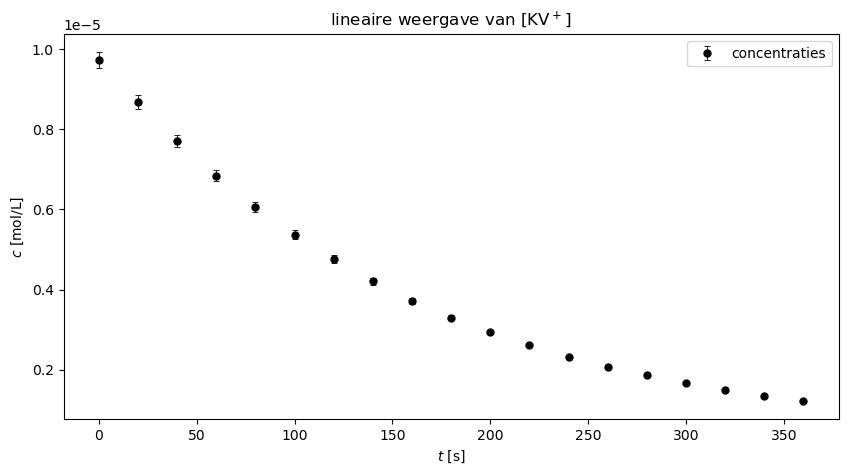

In [7]:
fig, ax = plt.subplots(figsize = (10, 5))
t = np.linspace(0,360,19)
ax.errorbar(t, c6, yerr=dc6, label="concentraties",
                marker="o", markersize=5, fmt=" ", color="black", ecolor="black", capsize=2, capthick=0.6, linewidth=0.6)
ax.set_xlabel(r'$t$ [s]')
ax.set_ylabel(r'$c$ [mol/L]')
ax.set_title(r'lineaire weergave van [KV$^+$]')
ax.legend()



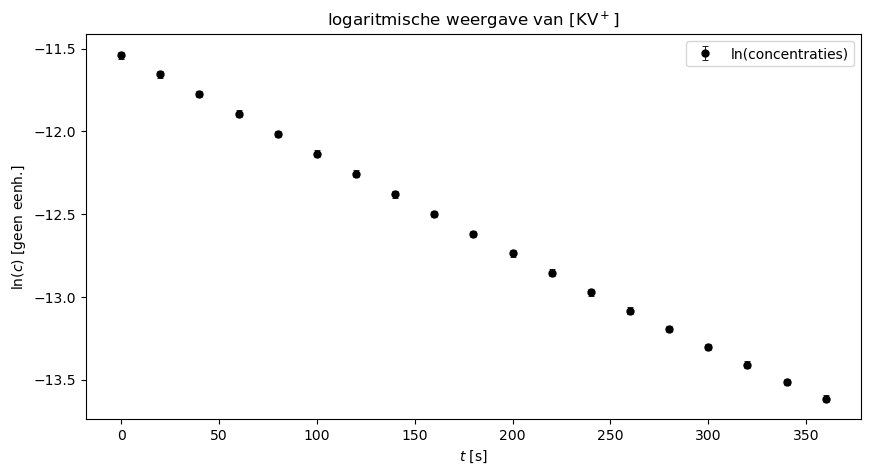

In [8]:
fig, ax = plt.subplots(figsize = (10, 5))
t = np.linspace(0,360,19)
ax.errorbar(t, np.log(c6), yerr=dlogc6, label="ln(concentraties)",
                marker="o", markersize=5, fmt=" ", color="black", ecolor="black", capsize=2, capthick=0.6, linewidth=0.6)
ax.set_xlabel(r'$t$ [s]')
ax.set_ylabel(r'ln($c$) [geen eenh.]')
ax.set_title(r'logaritmische weergave van [KV$^+$]')
ax.legend()

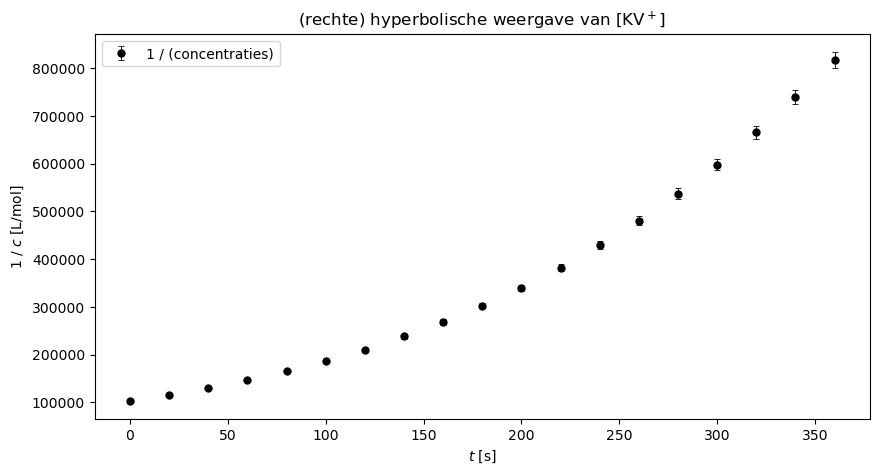

In [9]:
fig, ax = plt.subplots(figsize = (10, 5))
t = np.linspace(0,360,19)
ax.errorbar(t, 1 / c6, yerr=d1overc6, label="1 / (concentraties)",
                marker="o", markersize=5, fmt=" ", color="black", ecolor="black", capsize=2, capthick=0.6, linewidth=0.6)
ax.set_xlabel(r'$t$ [s]')
ax.set_ylabel(r'1 / $c$ [L/mol]')
ax.set_title(r'(rechte) hyperbolische weergave van [KV$^+$]')
ax.legend()


---------START--------------------------------------------------------------------------------------------------
For parameter R_0      :     Minimum at      -0.00002789     ;     68% CI = [     -0.00002789,      -0.00002668]
For parameter k        :     Minimum at      -0.00000010     ;     68% CI = [     -0.00000010,      -0.00000009]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min      655832.67373492
Reduced χ² value       :     χ²_red       38578.39257264
P-value                :     p-value          0.00000000
----------END---------------------------------------------------------------------------------------------------


---------START--------------------------------------------------------------------------------------------------


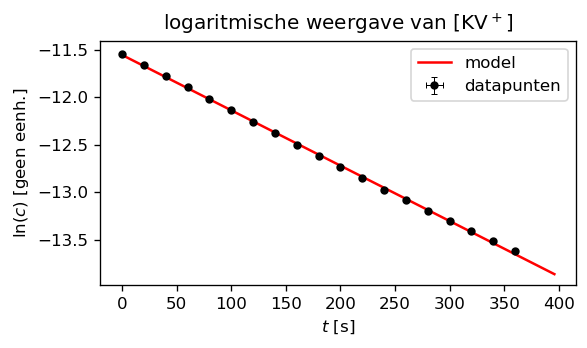

For parameter R_0      :     Minimum at     -11.55273928     ;     68% CI = [    -11.55966571,     -11.54581274]
For parameter k        :     Minimum at       0.00583125     ;     68% CI = [      0.00579839,       0.00586413]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min          11.19068828
Reduced χ² value       :     χ²_red           0.65827578
P-value                :     p-value          0.84648104


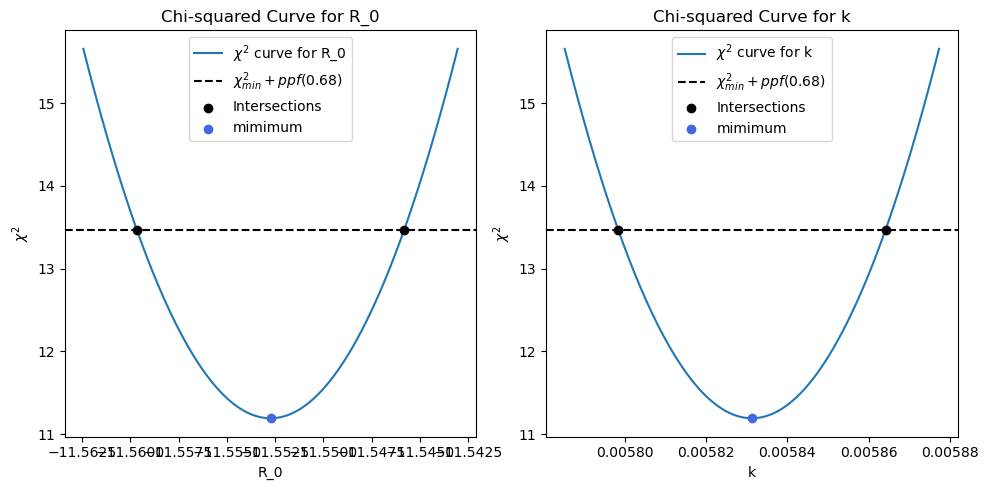

----------END---------------------------------------------------------------------------------------------------


---------START--------------------------------------------------------------------------------------------------
For parameter R_0      :     Minimum at   76299.19351046     ;     68% CI = [  74867.22689425,   77733.33627848]
For parameter k        :     Minimum at   -1411.39169029     ;     68% CI = [  -1425.41034612,   -1397.37356135]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min        1123.92442379
Reduced χ² value       :     χ²_red          66.11320140
P-value                :     p-value          0.00000000
----------END---------------------------------------------------------------------------------------------------



In [11]:
#fit NaOH 0.06M 

def model_m_0 (params , s):
    R_0, k = params
    return R_0 - k*s


param_names = ["R_0", "k"]
x = np.array(t).astype(float)
dx = np.zeros_like(x)
y = c6.astype(float)
dy = dc6.astype(float)

x_label = r'$t$ [s]'
y_label = r'ln($c$) [geen eenh.]'
title = r'logaritmische weergave van [KV$^+$]'

X_sq(((x, dx), (y, dy)), param_names, (-11, -5e-3), model_m_0, PLOT = False)

y = np.log(c6).astype(float)
dy = dlogc6.astype(float)
X_sq(((x, dx), (y, dy)), param_names, (-11, -5e-3), model_m_0, PLOT = True, graf1_title= title, graf1_x_label=x_label, graf1_y_label=y_label)

y = (1 / c6).astype(float)
dy = d1overc6.astype(float)
X_sq(((x, dx), (y, dy)), param_names, (-11, -5e-3), model_m_0, PLOT = False)

In [13]:
def fout_t(k, dk):
    K = sp.symbols('K')
    T = sp.log(2) / K
    s_func = sp.sqrt(sp.diff(T, K)**2 * dk**2)
    return s_func.subs(K, k)

k = 0.00583125
dk = 0.00583125 - 0.00579839
t12 = sp.log(2) / k
dt12 = fout_t(k, dk)
print(sp.N(t12), sp.N(dt12))

118.867683697311 0.669837871175759



---------START--------------------------------------------------------------------------------------------------
For parameter R_0      :     Minimum at       0.00000627     ;     68% CI = [      0.00000369,       0.00000627]
For parameter k        :     Minimum at      -0.00000000     ;     68% CI = [     -0.00000000,       0.00000001]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min        7446.35709355
Reduced χ² value       :     χ²_red         465.39731835
P-value                :     p-value          0.00000000
----------END---------------------------------------------------------------------------------------------------


---------START--------------------------------------------------------------------------------------------------


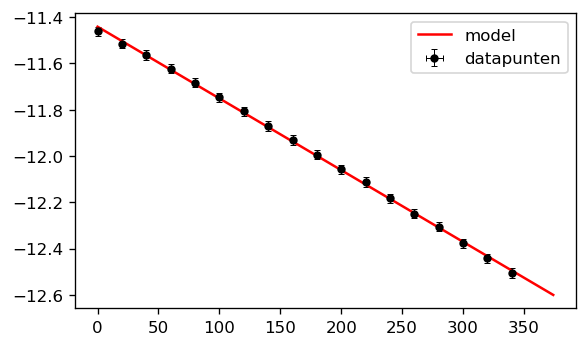

For parameter R_0      :     Minimum at     -11.44091235     ;     68% CI = [    -11.44802863,     -11.43379606]
For parameter k        :     Minimum at       0.00310083     ;     68% CI = [      0.00306511,       0.00313657]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min           2.81943577
Reduced χ² value       :     χ²_red           0.17621474
P-value                :     p-value          0.99988834


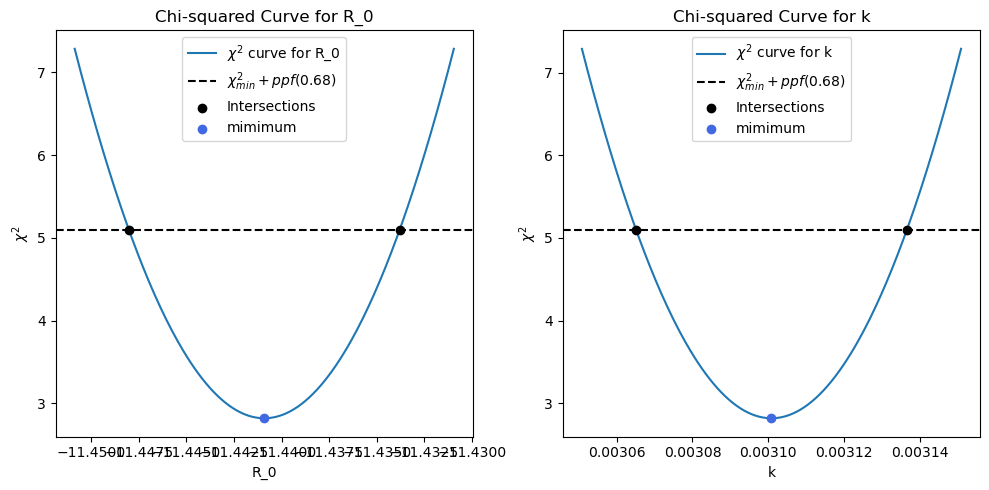

----------END---------------------------------------------------------------------------------------------------


---------START--------------------------------------------------------------------------------------------------
For parameter R_0      :     Minimum at   86061.30280956     ;     68% CI = [  85044.49268456,   87077.84358727]
For parameter k        :     Minimum at    -460.74543842     ;     68% CI = [   -467.87894220,    -453.61198541]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min         119.35505604
Reduced χ² value       :     χ²_red           7.45969100
P-value                :     p-value          0.00000000
----------END---------------------------------------------------------------------------------------------------



In [16]:
#fit NaOH 0.03M 
t = np.linspace(0, 340, 18)
def model_m_0 (params , s):
    R_0, k = params
    return R_0 - k*s


param_names = ["R_0", "k"]
x = np.array(t).astype(float)
dx = np.zeros_like(x)
y = c3.astype(float)
dy = dc3.astype(float)



X_sq(((x, dx), (y, dy)), param_names, (-11, -5e-3), model_m_0, PLOT = False)

y = np.log(c3).astype(float)
dy = dlogc3.astype(float)
X_sq(((x, dx), (y, dy)), param_names, (-11, -5e-3), model_m_0, PLOT = True)

y = (1 / c3).astype(float)
dy = d1overc3.astype(float)
X_sq(((x, dx), (y, dy)), param_names, (-11, -5e-3), model_m_0, PLOT = False)

In [17]:
def fout_R0(lnR0, dlnR0):
    ln = sp.symbols('ln')
    R0 = sp.exp(ln)
    s_func = sp.sqrt(sp.diff(R0, ln)**2 * dlnR0**2)
    return s_func.subs(ln, lnR0)

lnR0 = -11.44091235
dlnR0 = lnR0 + 11.44802863

R0 = sp.exp(lnR0)
dR0 = fout_R0(lnR0, dlnR0)

print(R0, dR0)



1.07466943822908e-5 7.64764862988081e-8


In [22]:
k1 = 0.00583125
k2 = 0.00310083
R01 = 0.040
R02 = 0.020



print((sp.log(k1/k2, 10)) / sp.log(R01 / R02, 10))

0.911150742203428
